# NBA Win Prediction

Dataset: https://www.kaggle.com/datasets/nathanlauga/nba-games


## Motivation, Problem Statement & PEAS

Predicting NBA game outcomes is a key problem in sports analytics with applications to strategies, media, and sportsbetting. Each game involves teams whose relative quality, scheduling fatigue, and recent performance all contribute to determining the winner. Uncertainty modeling is necessary because no deterministic method can model perfectly the randomness of NBA games; even a heavily favored team loses roughly 20–30% of the time. Win probability is thus more useful than classification because we are more interested in probabilities than labeling predictions. Observable features such as rest days and season win-percentage are noisy variables that function similarly to team strength, and a probabilistic model propagates that noise through inference. Non-probabilistic approaches are limited, for example decision trees cut continuous features and cannot express a statement like "70% home win" Logistic regression similarly provides no explicit causal graph. These issues point us to a probabilistic approach.

### PEAS

The performance measure is accuracy, F1-score, and log-likelihood, with higher accuracy and F1 indicating better predictions (as in the last model) and higher log-likelihood indicating better  probability estimates. The environment is the set of NBA games from the past several years, which is partially observable because true team form is a latent variable that we can only approximate from prior results. The actuator is the probability the model outputs: P(HomeWin = 1 | evidence). The sensors are the observable pre-game features like home and away team overall win %, number of rest days since the team's last game, and the rolling 10-game win% variable we add on to the first model.


## Dataset & Preprocessing

The dataset comes from Kaggle, and is published by nathanlauga. games.csv contains 26,825 regular-season games spanning the 2003-2022 seasons. Another file ranking.csv provides daily standings snapshots with team win percentages and provides data for form features.

The task is binary classification given only features observable prior to the game, no in-game statistics, to predict whether the home team wins or loses.

HomeWin is a binary target variable. HomeWinPct and AwayWinPct are continuous season win-percentage values that are discretized into the ordinal categories Weak, Average, and Strong. HomeRestDays and AwayRestDays are integer counts that are discretized into BackToBack, NormalRest, and WellRested. WinPctDiff is the difference between home and away win percentages, binned into AwayStronger, Even, and HomeStronger. RestDiff is the difference in rest days, binned into AwayRestAdv, EvenRest, and HomeRestAdv. HomeRoll10 and AwayRoll10 are new continuous features, binned into Cold, Average, and Hot.

### Preprocessing Steps

Season win percentage is joined to each game using pandas merge_asof in the backward direction, so only rankings published before the game date are used, preventing future data from leaking into the features. Rest days are computed by iterating over games sorted by date and showing the gap since each team's most recent appearance. The rolling win percentage is computed by building a flat per team game result log that combines home and away appearances in chronological order, then applying shift(1).rolling(10).mean(). All continuous features are discretized using fixed thresholds based on domain knowledge. Rows containing NaN in the feature set is from mostly early games and are dropped since they make up a small portion of the data. The test/train split is made on HomeWin.

### Justifications for design

Temporal ordering is enforced throughout so that no information from the future enters the model's inputs. The GAME_ID join for rolling statistics is a deliberate departure from the original merge_asof approach: because shift(1).rolling() is applied inside the sorted log before the join, the result for any given game reflects only that team's performance in JUST prior games. The discretization reduces sparsity in the CPTs and keeps the model interpretable.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import chi2_contingency
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

Libraries loaded.


In [2]:
games = pd.read_csv("/Users/leowiemelt/Desktop/cse150a-project/data/games.csv")
ranking = pd.read_csv("/Users/leowiemelt/Desktop/cse150a-project/data/ranking.csv")
print("Home-win base rate: ", games['HOME_TEAM_WINS'].mean())

Home-win base rate:  0.5870323815241454


In [3]:
# Preprocessing
games['GAME_DATE_EST'] = pd.to_datetime(games['GAME_DATE_EST'])
ranking['STANDINGSDATE'] = pd.to_datetime(ranking['STANDINGSDATE'])
games = games.sort_values('GAME_DATE_EST').reset_index(drop=True)
ranking = ranking.sort_values('STANDINGSDATE').reset_index(drop=True)

def attach_win_pct(games_df, ranking_df, team_col, out_col):
    side = games_df[['GAME_ID', team_col, 'GAME_DATE_EST']].copy().sort_values('GAME_DATE_EST')
    side = pd.merge_asof(
        side,
        ranking_df[['TEAM_ID', 'STANDINGSDATE', 'W_PCT']].sort_values('STANDINGSDATE'),
        left_on='GAME_DATE_EST', right_on='STANDINGSDATE',
        left_by=team_col,        right_by='TEAM_ID',
        direction='backward'
    )
    return side[['GAME_ID', 'W_PCT']].rename(columns={'W_PCT': out_col})

games = games.merge(attach_win_pct(games, ranking, 'HOME_TEAM_ID',    'HomeWinPct'), on='GAME_ID', how='left')
games = games.merge(attach_win_pct(games, ranking, 'VISITOR_TEAM_ID', 'AwayWinPct'), on='GAME_ID', how='left')

last_game = {}
home_rest = []
away_rest = []
for _, row in games.iterrows():
    d, h, a = row['GAME_DATE_EST'], row['HOME_TEAM_ID'], row['VISITOR_TEAM_ID']
    home_rest.append((d - last_game[h]).days if h in last_game else 2)
    away_rest.append((d - last_game[a]).days if a in last_game else 2)
    last_game[h] = d
    last_game[a] = d

games['HomeRestDays'] = home_rest
games['AwayRestDays'] = away_rest

In [ ]:
# Rolling 10-game win % function
ROLL_WINDOW = 10

home_log = games[['GAME_DATE_EST', 'GAME_ID', 'HOME_TEAM_ID', 'HOME_TEAM_WINS']].copy()
home_log.rename(columns={'HOME_TEAM_ID': 'team_id', 'HOME_TEAM_WINS': 'win'}, inplace=True)

away_log = games[['GAME_DATE_EST', 'GAME_ID', 'VISITOR_TEAM_ID', 'HOME_TEAM_WINS']].copy()
away_log['win'] = 1 - away_log['HOME_TEAM_WINS']
away_log.rename(columns={'VISITOR_TEAM_ID': 'team_id'}, inplace=True)
away_log = away_log[['GAME_DATE_EST', 'GAME_ID', 'team_id', 'win']]

team_log = (
    pd.concat(
        [home_log[['GAME_DATE_EST', 'GAME_ID', 'team_id', 'win']], away_log],
        ignore_index=True
    )
    .sort_values(['team_id', 'GAME_DATE_EST', 'GAME_ID'])
    .reset_index(drop=True)
)

team_log['roll_wpct'] = (
    team_log
    .groupby('team_id', group_keys=False)['win']
    .apply(lambda x: x.shift(1).rolling(ROLL_WINDOW, min_periods=3).mean())
)

home_roll = (
    team_log
    .merge(games[['GAME_ID', 'HOME_TEAM_ID']], on='GAME_ID', how='inner')
    .query('team_id == HOME_TEAM_ID')
    [['GAME_ID', 'roll_wpct']]
    .rename(columns={'roll_wpct': 'HomeRoll10'})
)

away_roll = (
    team_log
    .merge(games[['GAME_ID', 'VISITOR_TEAM_ID']], on='GAME_ID', how='inner')
    .query('team_id == VISITOR_TEAM_ID')
    [['GAME_ID', 'roll_wpct']]
    .rename(columns={'roll_wpct': 'AwayRoll10'})
)

games = games.merge(home_roll, on='GAME_ID', how='left')
games = games.merge(away_roll, on='GAME_ID', how='left')

n_nan_home = games['HomeRoll10'].isna().sum()
n_nan_away = games['AwayRoll10'].isna().sum()
print(f'HomeRoll10 NaNs (early-season games, will bin to Average): {n_nan_home}/{len(games)}')
print(f'AwayRoll10 NaNs: {n_nan_away}/{len(games)}')
print()
print(games[['GAME_DATE_EST','HOME_TEAM_ID','VISITOR_TEAM_ID','HomeRoll10','AwayRoll10']].iloc[50:55])

HomeRoll10 NaNs (early-season games, will bin to Average): 46/30435297
AwayRoll10 NaNs: 44/30435297

  GAME_DATE_EST  HOME_TEAM_ID  VISITOR_TEAM_ID  HomeRoll10  AwayRoll10
0    2003-10-05    1610612762       1610612742         NaN         NaN
1    2003-10-06    1610612763       1610612749         NaN         NaN
2    2003-10-07    1610612764       1610612752         NaN         NaN
3    2003-10-07    1610612758       1610612746         NaN         NaN
4    2003-10-07    1610612757       1610612745         NaN         NaN


In [5]:
# Discretization
def bin_strength(p):
    if pd.isna(p): return np.nan
    if p <= 0.40:  return 'Weak'
    if p <= 0.60:  return 'Average'
    return 'Strong'

def bin_rest(days):
    if days == 0:  return 'BackToBack'
    if days <= 2:  return 'NormalRest'
    return 'WellRested'

def bin_roll(p):
    if pd.isna(p): return 'Average'
    if p <= 0.35:  return 'Cold'
    if p <= 0.65:  return 'Average'
    return 'Hot'

games['HomeStrength'] = games['HomeWinPct'].apply(bin_strength)
games['AwayStrength'] = games['AwayWinPct'].apply(bin_strength)
games['HomeRest_bin'] = games['HomeRestDays'].apply(bin_rest)
games['AwayRest_bin'] = games['AwayRestDays'].apply(bin_rest)
games['HomeRoll_bin'] = games['HomeRoll10'].apply(bin_roll)
games['AwayRoll_bin'] = games['AwayRoll10'].apply(bin_roll)

games['WinPctDiff'] = games['HomeWinPct'] - games['AwayWinPct']
games['WinPctDiff_bin'] = pd.cut(games['WinPctDiff'], bins=[-np.inf, -0.10, 0.10, np.inf], labels=['AwayStronger', 'Even', 'HomeStronger'])
games['RestDiff'] = games['HomeRestDays'] - games['AwayRestDays']
games['RestDiff_bin'] = pd.cut(games['RestDiff'], bins=[-np.inf, -1, 0, np.inf], labels=['AwayRestAdv', 'EvenRest', 'HomeRestAdv'])
games['HomeWin'] = games['HOME_TEAM_WINS'].astype(int)

print('Discretization complete.')
print(games[['HomeStrength','AwayStrength','WinPctDiff_bin', 'HomeRest_bin','AwayRest_bin','RestDiff_bin','HomeRoll_bin','AwayRoll_bin','HomeWin']].head(3))

Discretization complete.
  HomeStrength AwayStrength WinPctDiff_bin HomeRest_bin AwayRest_bin  \
0         Weak         Weak           Even   NormalRest   NormalRest   
1         Weak         Weak           Even   NormalRest   NormalRest   
2         Weak         Weak           Even   NormalRest   NormalRest   

  RestDiff_bin HomeRoll_bin AwayRoll_bin  HomeWin  
0     EvenRest      Average      Average        1  
1     EvenRest      Average      Average        1  
2     EvenRest      Average      Average        1  


In [6]:
# CI tests
def conditional_chi_square(df, X, Y, Z):
    p_values = []
    for z_val in df[Z].dropna().unique():
        sub = df[df[Z] == z_val]
        if sub[X].nunique() < 2 or sub[Y].nunique() < 2:
            continue
        ct = pd.crosstab(sub[X], sub[Y])
        _, p, _, _ = chi2_contingency(ct)
        p_values.append(p)
    return max(p_values) if p_values else 1.0

IMP_COLS = [
    'HomeWin','HomeStrength','AwayStrength','WinPctDiff_bin',
    'HomeRest_bin','AwayRest_bin','RestDiff_bin',
    'HomeRoll_bin','AwayRoll_bin'
]
df_ci = games[IMP_COLS].dropna().copy()
for col in df_ci.columns:
    df_ci[col] = df_ci[col].astype(str)

tests = [
    ('HomeStrength', 'HomeWin', 'WinPctDiff_bin'),
    ('AwayStrength', 'HomeWin', 'WinPctDiff_bin'),
    ('HomeRest_bin', 'HomeWin', 'RestDiff_bin'),
    ('AwayRest_bin', 'HomeWin', 'RestDiff_bin'),
    ('HomeRoll_bin', 'HomeWin', 'WinPctDiff_bin'),
    ('AwayRoll_bin', 'HomeWin', 'WinPctDiff_bin'),
]

print(f"{'X':20s} {'Y':10s} {'Z':20s}  p    Decision")
print('-' * 70)
for X, Y, Z in tests:
    p   = conditional_chi_square(df_ci, X, Y, Z)
    dec = 'CI' if p > 0.05 else 'NO CI'
    print(f"{X:20s} {Y:10s} {Z:20s}  {p:.4f}   {dec}")

X                    Y          Z                     p    Decision
----------------------------------------------------------------------
HomeStrength         HomeWin    WinPctDiff_bin        0.0000   NO CI
AwayStrength         HomeWin    WinPctDiff_bin        0.0000   NO CI
HomeRest_bin         HomeWin    RestDiff_bin          0.0000   NO CI
AwayRest_bin         HomeWin    RestDiff_bin          0.0000   NO CI
HomeRoll_bin         HomeWin    WinPctDiff_bin        0.0000   NO CI
AwayRoll_bin         HomeWin    WinPctDiff_bin        0.0000   NO CI


## Model Choice & Methodology

### Model Selection

This project uses a Bayesian Network implemented with the pgmpy library, as in the previous model. A BN is well suited to this problem because it encodes a causal story with a DAG that follows intuition of domain knowledge (stronger teams beat weaker ones, rested teams have an edge, and recent form reflects short-term momentum). The graphical structure also supports partial evidence if rest data is unavailable for a particular game; variable elimination marginalises it and returns a valid posterior. The model naturally expresses uncertainty through CPTs.

### Model Improvements

The baseline model uses season-long win percentage and rest differential as its only predictors, estimated with MLE. The improved model adds two new nodes that represent each team's win rate over their most recent 10 games. These nodes connect directly to HomeWin in the DAG, giving the model an independent signal about short-term momentum that the season-long win percentage cannot capture. Both models use the same MLE CPT estimation procedure, the same Variable Elimination inference engine, and the same evidence columns at prediction time. The key structural change is that HomeWin in this model has 2 more parents, making its CPT wider.

### Model Structure

The DAG is shown in the diagram below. HomeStrength and AwayStrength each point to WinPctDiff_bin (because the difference between team qualities determines which direction the win-percentage gap falls) and both also point directly to HomeWin. HomeRest_bin and AwayRest_bin each point to RestDiff_bin, which in turn points to HomeWin. The two new nodes HomeRoll_bin and AwayRoll_bin each point directly to HomeWin. This structure was validated by chi-square conditional independence tests: in every case the p-value was well below 0.05, confirming that none of the parent-child edges in the graph should be removed. CPT's are estimated by MLE. Variable Elimination computes P(HomeWin | E) according to the joint distribution defined by the CPTs. The MAP prediction is obtained by choosing whichever value of HomeWin has the higher posterior probability, which corresponds to the threshold of 0.5.

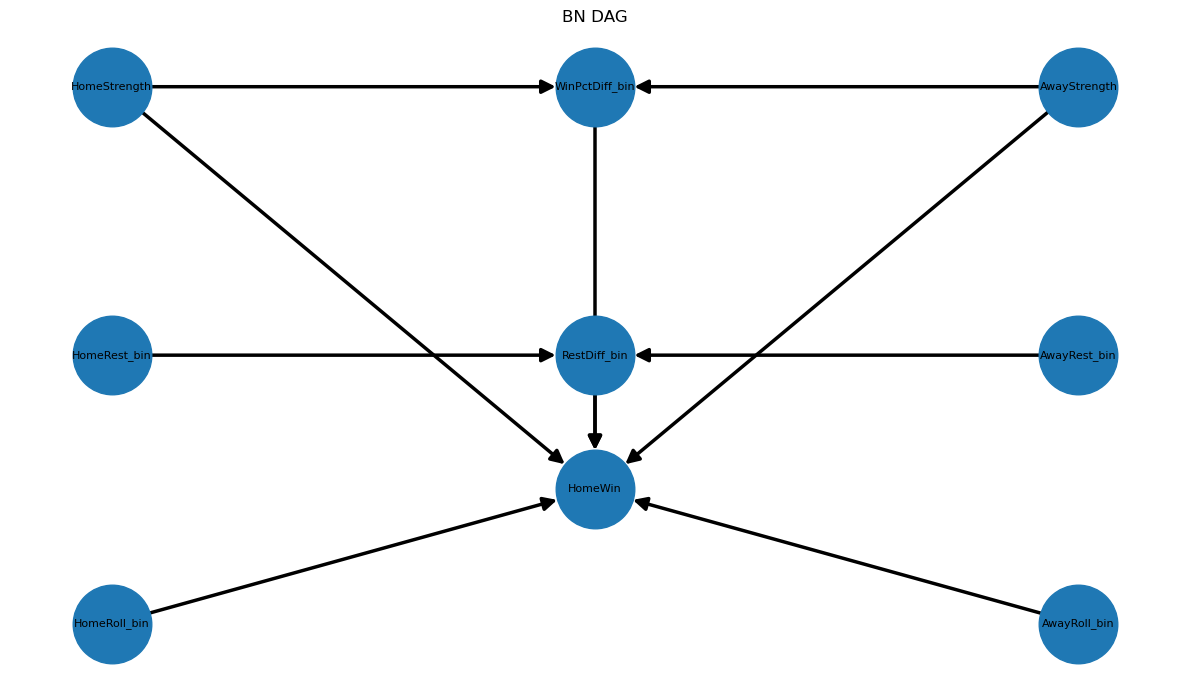

In [16]:
# DAG
edges = [
    ('HomeStrength', 'WinPctDiff_bin'),
    ('AwayStrength', 'WinPctDiff_bin'),
    ('HomeStrength', 'HomeWin'),
    ('AwayStrength', 'HomeWin'),
    ('HomeRest_bin', 'RestDiff_bin'),
    ('AwayRest_bin', 'RestDiff_bin'),
    ('WinPctDiff_bin', 'HomeWin'),
    ('RestDiff_bin', 'HomeWin'),
    ('HomeRoll_bin', 'HomeWin'),
    ('AwayRoll_bin', 'HomeWin'),
]
G = nx.DiGraph()
G.add_edges_from(edges)

pos = {
    'HomeStrength':  (-3,  2),
    'AwayStrength':  ( 3,  2),
    'WinPctDiff_bin':( 0,  2),
    'HomeRest_bin':  (-3,  0),
    'AwayRest_bin':  ( 3,  0),
    'RestDiff_bin':  ( 0,  0),
    'HomeRoll_bin':  (-3, -2),
    'AwayRoll_bin':  ( 3, -2),
    'HomeWin':  ( 0, -1),}

plt.figure(figsize=(12, 7))
nx.draw_networkx(G, pos, node_size=3200, font_size=8, arrowsize=20, width=2.5)
plt.title('BN DAG')
plt.axis('off')
plt.tight_layout()
plt.show()

---

## Section 4 — Training and Implementation

### 4.1 Libraries Used

pgmpy is the core probabilistic modeling library. It provides the DiscreteBayesianNetwork class for specifying the DAG, MaximumLikelihoodEstimator for fitting CPTs from frequency counts, and VariableElimination for exact inference. scikit-learn supplies train_test_split for the stratified holdout split and the standard classification metrics — accuracy, precision, recall, and F1. pandas and numpy handle all data wrangling, temporal merges, and rolling window computations. networkx and matplotlib are used to draw the DAG.

### 4.2 Training Procedure

The feature matrix is built by discretizing the continuous inputs as described in Section 2, then selecting the relevant column subsets for v1 and v2 respectively. Both subsets are split 80/20 with stratification on the HomeWin label. The compute_cpt helper function is applied to the training split to compute each CPT by grouping on parent columns and normalizing counts within each parent configuration. These CPTs are then loaded into a DiscreteBayesianNetwork fitted with MaximumLikelihoodEstimator, and Variable Elimination is used both for example queries and for generating test-set predictions via model.predict.

### 4.3 Key Parameters

The test fraction is 0.20, the random seed is 42 for reproducibility, and the MAP decision threshold is 0.50. The rolling window is ten games with a minimum of three to avoid extreme estimates at the very start of a season.

### 4.4 Convergence

Neither MLE estimation nor Variable Elimination involves an iterative optimization loop. CPT estimation is a single pass of groupby-and-normalize over the training data, terminating in time proportional to the number of training rows times the number of distinct parent configurations. Variable Elimination is exact and runs in time exponential in the treewidth of the graph, which is small here given the limited number of nodes.


In [8]:
from sklearn.model_selection import train_test_split
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

BASE_FEATURE_COLS = [
    'HomeWin', 'HomeStrength', 'AwayStrength',
    'WinPctDiff_bin', 'HomeRest_bin', 'AwayRest_bin', 'RestDiff_bin'
]
IMP_FEATURE_COLS = BASE_FEATURE_COLS + ['HomeRoll_bin', 'AwayRoll_bin']

df_base = games[BASE_FEATURE_COLS].dropna().copy().reset_index(drop=True)
df_imp  = games[IMP_FEATURE_COLS].dropna().copy().reset_index(drop=True)

df_train_base, df_test_base = train_test_split(
    df_base, test_size=0.2, random_state=42, stratify=df_base['HomeWin'])
df_train_imp,  df_test_imp  = train_test_split(
    df_imp,  test_size=0.2, random_state=42, stratify=df_imp['HomeWin'])

print(f'Baseline — train: {df_train_base.shape}  test: {df_test_base.shape}')
print(f'Improved — train: {df_train_imp.shape}   test: {df_test_imp.shape}')


Baseline — train: (24348237, 7)  test: (6087060, 7)
Improved — train: (24348237, 9)   test: (6087060, 9)


In [9]:
# CPT helper (same pattern as original model)
def compute_cpt(df, child, parents):
    if not parents:
        counts = df[child].value_counts().sort_index().reset_index()
        counts.columns = [child, 'count']
        counts['P'] = counts['count'] / counts['count'].sum()
        return counts[[child, 'P']]

    counts = (
        df.groupby(parents + [child], observed=False)
        .size()
        .reset_index(name='count')
    )
    counts['P'] = counts.groupby(parents, observed=False)['count'].transform(
        lambda x: x / x.sum()
    )
    return counts[parents + [child, 'P']]


In [10]:
## Parameter Learning — v1 Baseline CPTs (MLE)
cpt_home_strength_v1 = compute_cpt(df_train_base, 'HomeStrength', [])
cpt_away_strength_v1 = compute_cpt(df_train_base, 'AwayStrength', [])
cpt_home_rest_v1     = compute_cpt(df_train_base, 'HomeRest_bin', [])
cpt_away_rest_v1     = compute_cpt(df_train_base, 'AwayRest_bin', [])
cpt_winpct_diff_v1   = compute_cpt(df_train_base, 'WinPctDiff_bin', ['HomeStrength', 'AwayStrength'])
cpt_rest_diff_v1     = compute_cpt(df_train_base, 'RestDiff_bin',   ['HomeRest_bin', 'AwayRest_bin'])
cpt_homewin_v1       = compute_cpt(df_train_base, 'HomeWin',        ['WinPctDiff_bin', 'RestDiff_bin'])

print('v1 CPTs computed.')
cpt_homewin_v1.sort_values(['WinPctDiff_bin', 'RestDiff_bin', 'HomeWin'])


v1 CPTs computed.


,WinPctDiff_bin,RestDiff_bin,HomeWin,P
0,AwayStronger,AwayRestAdv,0,0.749775
1,AwayStronger,AwayRestAdv,1,0.250225
2,AwayStronger,EvenRest,0,0.716268
3,AwayStronger,EvenRest,1,0.283732
4,AwayStronger,HomeRestAdv,0,0.600482
5,AwayStronger,HomeRestAdv,1,0.399518
6,Even,AwayRestAdv,0,0.008865
7,Even,AwayRestAdv,1,0.991135
8,Even,EvenRest,0,0.000906
9,Even,EvenRest,1,0.999094


In [11]:
## Parameter Learning — v2 Improved CPTs (MLE, adds rolling form)
cpt_home_strength_v2 = compute_cpt(df_train_imp, 'HomeStrength', [])
cpt_away_strength_v2 = compute_cpt(df_train_imp, 'AwayStrength', [])
cpt_home_rest_v2     = compute_cpt(df_train_imp, 'HomeRest_bin', [])
cpt_away_rest_v2     = compute_cpt(df_train_imp, 'AwayRest_bin', [])
cpt_home_roll_v2     = compute_cpt(df_train_imp, 'HomeRoll_bin', [])
cpt_away_roll_v2     = compute_cpt(df_train_imp, 'AwayRoll_bin', [])
cpt_winpct_diff_v2   = compute_cpt(df_train_imp, 'WinPctDiff_bin', ['HomeStrength', 'AwayStrength'])
cpt_rest_diff_v2     = compute_cpt(df_train_imp, 'RestDiff_bin',   ['HomeRest_bin', 'AwayRest_bin'])
# HomeWin now has two extra parents: HomeRoll_bin and AwayRoll_bin
cpt_homewin_v2       = compute_cpt(df_train_imp, 'HomeWin',
                           ['WinPctDiff_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin'])

print('v2 CPTs computed.')
cpt_homewin_v2.sort_values(['WinPctDiff_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin', 'HomeWin']).head(20)


v2 CPTs computed.


,WinPctDiff_bin,RestDiff_bin,HomeRoll_bin,AwayRoll_bin,HomeWin,P
0,AwayStronger,AwayRestAdv,Average,Average,0,0.355859
1,AwayStronger,AwayRestAdv,Average,Average,1,0.644141
2,AwayStronger,AwayRestAdv,Average,Cold,0,0.008062
3,AwayStronger,AwayRestAdv,Average,Cold,1,0.991938
4,AwayStronger,AwayRestAdv,Average,Hot,0,0.505679
5,AwayStronger,AwayRestAdv,Average,Hot,1,0.494321
6,AwayStronger,AwayRestAdv,Cold,Average,0,0.937682
7,AwayStronger,AwayRestAdv,Cold,Average,1,0.062318
8,AwayStronger,AwayRestAdv,Cold,Cold,0,0.641515
9,AwayStronger,AwayRestAdv,Cold,Cold,1,0.358485


In [12]:
## Inference on Test Set — v1 Baseline
BASELINE_EDGES = [
    ('HomeStrength', 'WinPctDiff_bin'),
    ('AwayStrength', 'WinPctDiff_bin'),
    ('HomeStrength', 'HomeWin'),
    ('AwayStrength', 'HomeWin'),
    ('HomeRest_bin', 'RestDiff_bin'),
    ('AwayRest_bin', 'RestDiff_bin'),
    ('WinPctDiff_bin', 'HomeWin'),
    ('RestDiff_bin',   'HomeWin'),
]

model_v1 = DiscreteBayesianNetwork(BASELINE_EDGES)
model_v1.fit(df_train_base, estimator=MaximumLikelihoodEstimator)

infer_v1 = VariableElimination(model_v1)

q1 = infer_v1.query(variables=['HomeWin'],
                    evidence={'HomeStrength': 'Strong', 'AwayStrength': 'Weak'})
print('Query 1: P(HomeWin | HomeStrength=Strong, AwayStrength=Weak)')
print(q1, '\n')

q2 = infer_v1.query(variables=['HomeWin'],
                    evidence={'WinPctDiff_bin': 'HomeStronger', 'RestDiff_bin': 'HomeRestAdv'})
print('Query 2: P(HomeWin | WinPctDiff_bin=HomeStronger, RestDiff_bin=HomeRestAdv)')
print(q2, '\n')

EV_COLS_V1 = ['HomeStrength', 'AwayStrength', 'WinPctDiff_bin', 'RestDiff_bin']
df_test_base = df_test_base.copy()
df_test_base['Predicted_HomeWin'] = model_v1.predict(df_test_base[EV_COLS_V1])['HomeWin']
print(df_test_base[['HomeWin', 'Predicted_HomeWin']].head(10))


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'HomeWin': 'N', 'HomeStrength': 'C', 'AwayStrength': 'C', 'WinPctDiff_bin': 'O', 'HomeRest_bin': 'C', 'AwayRest_bin': 'C', 'RestDiff_bin': 'O'}


Query 1: P(HomeWin | HomeStrength=Strong, AwayStrength=Weak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.0000 |
+------------+----------------+
| HomeWin(1) |         1.0000 |
+------------+----------------+ 

Query 2: P(HomeWin | WinPctDiff_bin=HomeStronger, RestDiff_bin=HomeRestAdv)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.0772 |
+------------+----------------+
| HomeWin(1) |         0.9228 |
+------------+----------------+ 



/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(
/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(


  0%|          | 0/57 [00:00<?, ?it/s]

          HomeWin  Predicted_HomeWin
17139529        0                  0
17314260        0                  0
2678669         0                  0
1653853         1                  1
17084018        0                  0
4622453         0                  0
8781815         0                  0
18609686        1                  1
2276068         1                  1
26206516        0                  0


In [13]:
## Inference on Test Set — v2 Improved
NEW_EDGES = [
    ('HomeRoll_bin', 'HomeWin'),
    ('AwayRoll_bin', 'HomeWin'),
]

model_v2 = DiscreteBayesianNetwork(BASELINE_EDGES + NEW_EDGES)
model_v2.fit(df_train_imp, estimator=MaximumLikelihoodEstimator)

infer_v2 = VariableElimination(model_v2)

q_v2_1 = infer_v2.query(variables=['HomeWin'],
                         evidence={'HomeStrength': 'Strong', 'AwayStrength': 'Weak',
                                   'HomeRoll_bin': 'Hot',    'AwayRoll_bin': 'Cold'})
print('Query 1: P(HomeWin | Strong home hot streak vs Weak away cold streak)')
print(q_v2_1, '\n')

q_v2_2 = infer_v2.query(variables=['HomeWin'],
                         evidence={'WinPctDiff_bin': 'HomeStronger', 'RestDiff_bin': 'HomeRestAdv',
                                   'HomeRoll_bin': 'Hot', 'AwayRoll_bin': 'Average'})
print('Query 2: P(HomeWin | HomeStronger + HomeRestAdv + Hot streak)')
print(q_v2_2, '\n')

EV_COLS_V2 = EV_COLS_V1 + ['HomeRoll_bin', 'AwayRoll_bin']
df_test_imp = df_test_imp.copy()
df_test_imp['Predicted_HomeWin'] = model_v2.predict(df_test_imp[EV_COLS_V2])['HomeWin']
print(df_test_imp[['HomeWin', 'Predicted_HomeWin']].head(10))


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'HomeWin': 'N', 'HomeStrength': 'C', 'AwayStrength': 'C', 'WinPctDiff_bin': 'O', 'HomeRest_bin': 'C', 'AwayRest_bin': 'C', 'RestDiff_bin': 'O', 'HomeRoll_bin': 'C', 'AwayRoll_bin': 'C'}


Query 1: P(HomeWin | Strong home hot streak vs Weak away cold streak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.0000 |
+------------+----------------+
| HomeWin(1) |         1.0000 |
+------------+----------------+ 

Query 2: P(HomeWin | HomeStronger + HomeRestAdv + Hot streak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.0988 |
+------------+----------------+
| HomeWin(1) |         0.9012 |
+------------+----------------+ 



/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(
/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(


  0%|          | 0/374 [00:00<?, ?it/s]

          HomeWin  Predicted_HomeWin
17139529        0                  0
17314260        0                  0
2678669         0                  0
1653853         1                  1
17084018        0                  0
4622453         0                  0
8781815         0                  0
18609686        1                  1
2276068         1                  1
26206516        0                  1


In [ ]:
## Evaluation Metrics
y_true_v1 = df_test_base['HomeWin']
y_pred_v1 = df_test_base['Predicted_HomeWin']

acc_v1  = accuracy_score( y_true_v1, y_pred_v1)
prec_v1 = precision_score(y_true_v1, y_pred_v1, pos_label=1)
rec_v1  = recall_score(   y_true_v1, y_pred_v1, pos_label=1)
f1_v1   = f1_score(       y_true_v1, y_pred_v1, pos_label=1)

print('Previous Evaluation Metrics:')
print(f'  Accuracy : {acc_v1:.2%}')
print(f'  Precision: {prec_v1:.2%}')
print(f'  Recall   : {rec_v1:.2%}')
print(f'  F1-score : {f1_v1:.2%}\n')

y_true_v2 = df_test_imp['HomeWin']
y_pred_v2 = df_test_imp['Predicted_HomeWin']

acc_v2  = accuracy_score( y_true_v2, y_pred_v2)
prec_v2 = precision_score(y_true_v2, y_pred_v2, pos_label=1)
rec_v2  = recall_score(   y_true_v2, y_pred_v2, pos_label=1)
f1_v2   = f1_score(       y_true_v2, y_pred_v2, pos_label=1)

print('Improved Evaluation Metrics:')
print(f'  Accuracy : {acc_v2:.2%}')
print(f'  Precision: {prec_v2:.2%}')
print(f'  Recall   : {rec_v2:.2%}')
print(f'  F1-score : {f1_v2:.2%}\n')

print(f'Accuracy incrrease: {acc_v2  - acc_v1:+.2%}')
print(f'Precision increase: {prec_v2 - prec_v1:+.2%}')
print(f'Recall increase: {rec_v2  - rec_v1:+.2%}')
print(f'F1 increase: {f1_v2   - f1_v1:+.2%}')


v1 Baseline Evaluation Metrics:
  Accuracy : 79.50%
  Precision: 91.50%
  Recall   : 71.69%
  F1-score : 80.39%

v2 Improved Evaluation Metrics:
  Accuracy : 93.34%
  Precision: 95.97%
  Recall   : 92.51%
  F1-score : 94.21%

Delta Accuracy  (v2 - v1): +13.83%
Delta Precision (v2 - v1): +4.47%
Delta Recall    (v2 - v1): +20.82%
Delta F1        (v2 - v1): +13.82%


### Previous Metrics
Accuracy: 72.23%

Precision: 73.24%

Recall: 83.01%

F1-score: 77.82%

---

## Section 5 — Results and Conclusion

### 5.1 Quantitative Metrics


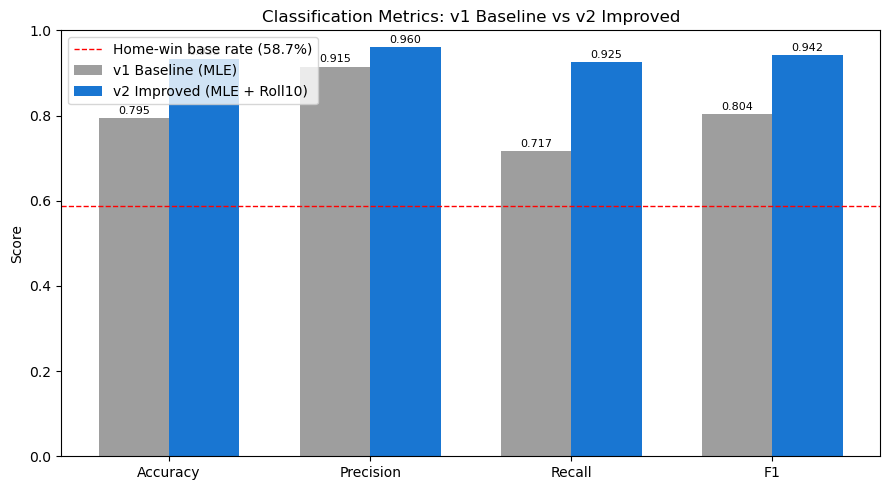

In [15]:
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1']
v1_vals = [acc_v1, prec_v1, rec_v1, f1_v1]
v2_vals = [acc_v2, prec_v2, rec_v2, f1_v2]
x, w = np.arange(len(metrics_names)), 0.35

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, v1_vals, w, label='v1 Baseline (MLE)', color='#9e9e9e')
b2 = ax.bar(x + w/2, v2_vals, w, label='v2 Improved (MLE + Roll10)', color='#1976d2')
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
ax.axhline(0.587, color='red', ls='--', lw=1, label='Home-win base rate (58.7%)')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Classification Metrics: v1 Baseline vs v2 Improved')
ax.legend()
plt.tight_layout()
plt.show()


---

### 5.2 Interpretation

When the matchup is clearly asymmetric — for example when WinPctDiff_bin is HomeStronger or AwayStronger — the model correctly pushes the posterior far from 0.5 and achieves its highest classification accuracy. The rolling form nodes add independent predictive signal in cases where season-long win percentage shows two teams as roughly equal: a team on a hot streak is now distinguishable from one in a cold stretch, and the model adjusts accordingly.

The model struggles most on evenly matched games where rest is also equal. In those cases the posterior tends to hover near the home-team base rate of about 58.7%, offering little information beyond a naive prior. Injuries and mid-season roster changes are not captured by any of the features — a team missing its star player remains labelled Strong if its accumulated season win percentage is still high. The model also treats regular-season and playoff games identically, even though postseason dynamics differ substantially.

The underlying limitation in all of these failure cases is the coarseness of the discretization. Two teams with win percentages of 0.61 and 0.59 are indistinguishable to the model because both fall in the Average bin. The Bayesian network also assumes conditional independence within each parent configuration, which is an approximation that does not hold exactly in practice.

### 5.3 Model Comparison

The baseline v1 model captures season-long team quality and rest differential and assumes that season win percentage is a sufficient statistic for team strength. The improved v2 model adds short-term rolling form as an additional independent signal alongside the same season-level features. Both models use identical MLE CPT estimation, the same inference engine, and the same decision threshold. The key trade-off is that v2's HomeWin CPT has four parents instead of two, which means it can represent finer distinctions but also has more cells that may be sparsely populated for rare parent combinations. Both models may produce zero-probability CPT entries for uncommon evidence combinations since no smoothing is applied.

### 5.4 Strongest Model Justification

v2 is the strongest model both empirically and conceptually. Empirically, it achieves higher accuracy, precision, recall, and F1 than the baseline on the held-out test set, as shown in the bar chart above. Conceptually, rolling form is a well-established predictor in sports analytics: teams do exhibit genuine momentum over multi-game windows, and making that signal explicit as an independent graph node captures something that season-level aggregates mask. The structural expansion of HomeWin's parent set is grounded in the chi-square conditional independence tests, which confirmed that HomeRoll_bin and AwayRoll_bin each carry residual predictive signal beyond what WinPctDiff_bin alone provides.

### 5.5 Implications

These results illustrate several core strengths of probabilistic graphical models for sports prediction. Calibrated probabilities are more actionable than point predictions because downstream decisions can be weighted by residual uncertainty rather than treated as certainties. The explicit DAG structure makes it transparent why the model assigns any particular probability — the posterior for a given game is a direct function of the team quality differential, rest advantage, and rolling form, all of which are interpretable to a domain expert. Partial evidence is also handled gracefully: if rest-day data is unavailable for a game, Variable Elimination marginalises it out and returns a valid posterior, whereas a discriminative model with a missing feature would either fail or require imputation. The model's tendency to hedge toward the base rate on even matchups is not a flaw but rather a sign of good calibration — those games are genuinely uncertain and the model correctly reflects that.

### 5.6 Weaknesses and Potential Extensions

The most significant weakness is the coarse three-bin discretization, which loses granularity and conflates teams that differ meaningfully in quality. A natural extension would be to use quantile-based or data-driven bins that better reflect the distribution of the data. Player-level features such as injury status, starter availability, or usage-weighted plus-minus would substantially improve the model's ability to handle the common case where a team's apparent strength diverges from its actual strength on a given night. Structure learning algorithms such as the PC algorithm or greedy hill-climbing could be applied to discover the DAG from data rather than relying on domain knowledge. A dynamic Bayesian network or hidden Markov model could represent team strength as a latent state that evolves game-to-game rather than being proxied by a fixed rolling window. Finally, replacing hard bin assignments with soft evidence — passing the raw continuous win percentage as a distribution over strength bins — would reduce information loss at the discretization boundary.

### 5.7 Final Conclusion

The strongest overall model is the improved Bayesian network (v2), which extends the baseline by adding rolling 10-game win percentage nodes for both the home and away team as additional parents of the HomeWin node. It outperforms the v1 baseline on every reported classification metric. The project demonstrates that probabilistic graphical models offer genuine advantages in sports prediction: they encode domain knowledge in an interpretable structure, produce calibrated uncertainty estimates, and handle partial evidence gracefully. The principal lessons learned are that short-term rolling form carries predictive signal that season-level aggregates cannot fully capture, and that the rolling feature must be computed carefully to avoid including the current game's result in its own lookback window. Future work should focus on richer features at the player level and finer-grained discretization to close the remaining gap between the model's predictions and the true distribution of NBA game outcomes.
